# Serie I: evaluación económica exploratoria

Este notebook convierte provisionalmente los rendimientos de ensayos de Louisiana en un aporte económico parcial por acre usando los supuestos del PDF. No es una recomendación final y no declara validados los cálculos: esa revisión debe comprobar unidades, fórmula, aplicación de costos e interpretación de negocio por separado. Los datos son ensayos externos, no resultados de fincas de Santa Ana.

In [1]:
import sys
print("Python de ejecución:", sys.executable)
from pathlib import Path
import numpy as np
import pandas as pd

RUTA_ETL = Path("../data/processed/serie1_etl_provisional.csv")
if not RUTA_ETL.exists():
    RUTA_ETL = Path("data/processed/serie1_etl_provisional.csv")
if not RUTA_ETL.exists():
    raise FileNotFoundError("Ejecuta primero: python scripts/etl_serie1.py")

datos_etl = pd.read_csv(RUTA_ETL, low_memory=False)
print(f"Archivo: {RUTA_ETL.as_posix()}")
print(f"Filas analíticas: {len(datos_etl):,}")

Python de ejecución: C:\Users\user\Desktop\Cursos\cesar\otros\yo\Prueba Santa Ana\.venv\Scripts\python.exe


Archivo: ../data/processed/serie1_etl_provisional.csv
Filas analíticas: 29,403


## 1. Supuestos y aporte parcial por observación

Supuestos referenciales del PDF: US$0.20 por libra de azúcar recuperable; US$14 por tonelada de caña para corte, alce y transporte; US$350 por acre de mantenimiento anual; y US$1,100 por acre de renovación en `CROP=0`. USDA define `T_SPACRE` en lb/acre y `TCA` en ton/acre. Sigue pendiente confirmar que la tonelada del costo referencial coincide con la de la fuente y revisar si el mantenimiento debe imputarse de esta forma a cada observación.

La fórmula provisional es `T_SPACRE × precio − TCA × costo por tonelada − mantenimiento − renovación si CROP=0`. Se llama **aporte económico parcial**, no utilidad neta, porque faltan otros costos. El precio de equilibrio por fila cubre únicamente los costos incluidos. Su distribución no es una distribución del precio del azúcar.

El cálculo conserva filas marcadas para revisión y muestra una sensibilidad descriptiva al excluirlas temporalmente. No se imputan valores ni se interpreta automáticamente una alerta como dato incorrecto.

In [2]:
precio_referencial = 0.20
costo_cosecha_por_ton = 14
costo_mantenimiento_por_acre = 350
costo_renovacion_por_acre = 1100

aporte = datos_etl.loc[datos_etl["STAGE"].eq(5)].dropna(subset=["T_SPACRE", "TCA"]).copy()
aporte["INGRESO_BRUTO_USD_ACRE"] = aporte["T_SPACRE"] * precio_referencial
aporte["COSTO_COSECHA_USD_ACRE"] = aporte["TCA"] * costo_cosecha_por_ton
aporte["COSTO_MANTENIMIENTO_USD_ACRE"] = costo_mantenimiento_por_acre
aporte["COSTO_RENOVACION_USD_ACRE"] = np.where(
    aporte["CROP"].eq(0), costo_renovacion_por_acre, 0
)
aporte["APORTE_PARCIAL_USD_ACRE"] = (
    aporte["INGRESO_BRUTO_USD_ACRE"]
    - aporte["COSTO_COSECHA_USD_ACRE"]
    - aporte["COSTO_MANTENIMIENTO_USD_ACRE"]
    - aporte["COSTO_RENOVACION_USD_ACRE"]
)
costos_considerados = (
    aporte["COSTO_COSECHA_USD_ACRE"]
    + aporte["COSTO_MANTENIMIENTO_USD_ACRE"]
    + aporte["COSTO_RENOVACION_USD_ACRE"]
)
aporte["PRECIO_EQUILIBRIO_USD_LB"] = costos_considerados.div(
    aporte["T_SPACRE"].where(aporte["T_SPACRE"].gt(0))
)

resumen_aporte = aporte.groupby("CROP").agg(
    registros_completos=("APORTE_PARCIAL_USD_ACRE", "size"),
    clones=("CLONE", "nunique"),
    anios=("YEAR", "nunique"),
    localidades=("LOC", "nunique"),
    mediana_aporte_usd_acre=("APORTE_PARCIAL_USD_ACRE", "median"),
    promedio_aporte_usd_acre=("APORTE_PARCIAL_USD_ACRE", "mean"),
    porcentaje_aporte_positivo=("APORTE_PARCIAL_USD_ACRE", lambda s: s.gt(0).mean() * 100),
    filas_marcadas=("REQUIERE_REVISION", "sum"),
)
precio_equilibrio = aporte.groupby("CROP")["PRECIO_EQUILIBRIO_USD_LB"].quantile([0.1, 0.5, 0.9]).unstack()
precio_equilibrio.columns = ["precio_equilibrio_p10", "precio_equilibrio_mediano", "precio_equilibrio_p90"]
resumen_aporte = resumen_aporte.join(precio_equilibrio).round(2)
display(resumen_aporte)

sin_marcadas = aporte.loc[~aporte["REQUIERE_REVISION"]]
medianas_sin_marcadas = sin_marcadas.groupby("CROP")["APORTE_PARCIAL_USD_ACRE"].median().rename("mediana_sin_filas_marcadas")
sensibilidad_revision = resumen_aporte[["mediana_aporte_usd_acre"]].join(medianas_sin_marcadas)
sensibilidad_revision["cambio_mediana_usd_acre"] = (
    sensibilidad_revision["mediana_sin_filas_marcadas"]
    - sensibilidad_revision["mediana_aporte_usd_acre"]
)
print("Sensibilidad descriptiva a retirar temporalmente filas marcadas:")
display(sensibilidad_revision.round(2))
print("La ejecución reproduce el cálculo; no constituye su validación técnica o económica.")

,registros_completos,clones,anios,localidades,mediana_aporte_usd_acre,promedio_aporte_usd_acre,porcentaje_aporte_positivo,filas_marcadas,precio_equilibrio_p10,precio_equilibrio_mediano,precio_equilibrio_p90
CROP,,,,,,,,,,,
0,4527,37,12,15,-69.60,-74.93,40.95,0,0.17,0.21,0.28
1,3871,23,12,14,920.99,910.45,99.46,2,0.08,0.09,0.12
2,3609,26,12,14,709.60,720.03,98.64,2,0.08,0.10,0.14
3,1942,22,12,12,619.20,624.78,97.84,0,0.09,0.11,0.14
4,84,13,3,1,617.68,609.45,98.81,0,0.09,0.11,0.15


Sensibilidad descriptiva a retirar temporalmente filas marcadas:


,mediana_aporte_usd_acre,mediana_sin_filas_marcadas,cambio_mediana_usd_acre
CROP,,,
0,-69.60,-69.60,0.00
1,920.99,921.21,0.22
2,709.60,709.80,0.20
3,619.20,619.20,0.00
4,617.68,617.68,-0.00


La ejecución reproduce el cálculo; no constituye su validación técnica o económica.


## 2. Comparación de clones dentro del mismo ambiente

La mediana directa mezcla años y localidades. Para una primera pantalla, se resume cada clon por `CROP`, `YEAR` y `LOC` con la mediana de sus repeticiones; después se compara con la mediana de clones observados en ese mismo ciclo, año y localidad. Una diferencia positiva indica aporte parcial superior a la mediana del ambiente. Se muestran soporte temporal y geográfico, pero esto no elimina sesgos del diseño ni permite una conclusión causal.

No se eligen clones automáticamente. Los resultados son una lista para revisión: la certeza depende también de cuántos años y localidades respaldan cada ciclo, de la estabilidad, del estado de liberación del clon y de la transferencia a Guatemala.

In [3]:
clon_ambiente = aporte.groupby(
    ["CLONE", "CROP", "YEAR", "LOC"], as_index=False
).agg(APORTE_PARCIAL_USD_ACRE=("APORTE_PARCIAL_USD_ACRE", "median"))
centro_ambiente = clon_ambiente.groupby(
    ["CROP", "YEAR", "LOC"]
)["APORTE_PARCIAL_USD_ACRE"].median().rename("MEDIANA_AMBIENTE")
clon_ambiente = clon_ambiente.join(centro_ambiente, on=["CROP", "YEAR", "LOC"])
clon_ambiente["DIFERENCIA_MEDIANA_AMBIENTE_USD_ACRE"] = (
    clon_ambiente["APORTE_PARCIAL_USD_ACRE"] - clon_ambiente["MEDIANA_AMBIENTE"]
)
resumen_clon_crop = clon_ambiente.groupby(["CLONE", "CROP"]).agg(
    ambientes=("DIFERENCIA_MEDIANA_AMBIENTE_USD_ACRE", "size"),
    anios=("YEAR", "nunique"),
    localidades=("LOC", "nunique"),
    aporte_mediano_usd_acre=("APORTE_PARCIAL_USD_ACRE", "median"),
    diferencia_mediana_ambiente_usd_acre=("DIFERENCIA_MEDIANA_AMBIENTE_USD_ACRE", "median"),
    iqr_diferencia_ambiente_usd_acre=("DIFERENCIA_MEDIANA_AMBIENTE_USD_ACRE", lambda s: s.quantile(0.75) - s.quantile(0.25)),
    porcentaje_ambientes_sobre_mediana=("DIFERENCIA_MEDIANA_AMBIENTE_USD_ACRE", lambda s: s.gt(0).mean() * 100),
).round(2)

clones_por_ambiente = clon_ambiente.groupby(["CROP", "YEAR", "LOC"]).size()
soporte_ambiente = clones_por_ambiente.groupby("CROP").agg(
    min_clones="min", mediana_clones="median", max_clones="max"
)
print("Clones disponibles por ambiente (CROP × año × localidad):")
display(soporte_ambiente)

for ciclo in [0, 1, 2, 3]:
    print()
    print(f"Ocho clones con mayor diferencia mediana frente a su ambiente, CROP={ciclo}:")
    display(
        resumen_clon_crop.xs(ciclo, level="CROP")
        .sort_values("diferencia_mediana_ambiente_usd_acre", ascending=False)
        .head(8)
    )

Clones disponibles por ambiente (CROP × año × localidad):


,min_clones,mediana_clones,max_clones
CROP,,,
0,7,11.0,15
1,7,10.0,12
2,6,10.0,13
3,7,9.0,12
4,9,9.0,10



Ocho clones con mayor diferencia mediana frente a su ambiente, CROP=0:


,ambientes,anios,localidades,aporte_mediano_usd_acre,diferencia_mediana_ambiente_usd_acre,iqr_diferencia_ambiente_usd_acre,porcentaje_ambientes_sobre_mediana
CLONE,,,,,,,
HO16-600,9,1,9,207.13,264.19,211.03,77.78
HOCP14-885,41,4,13,194.00,222.80,233.67,90.24
HOCP13-758,21,2,12,216.60,210.60,168.00,85.71
HO16-608,9,1,9,269.37,151.42,238.22,88.89
HO12-615,63,6,14,87.24,112.63,215.59,77.78
L13-251,11,1,11,90.60,93.20,41.50,81.82
HOL15-508,31,3,13,-70.11,62.04,183.10,74.19
L15-306,30,3,13,-14.95,61.46,212.49,60.00



Ocho clones con mayor diferencia mediana frente a su ambiente, CROP=1:


,ambientes,anios,localidades,aporte_mediano_usd_acre,diferencia_mediana_ambiente_usd_acre,iqr_diferencia_ambiente_usd_acre,porcentaje_ambientes_sobre_mediana
CLONE,,,,,,,
HOL15-508,21,2,12,946.30,100.53,156.12,80.95
L14-267,32,3,12,942.54,85.12,126.96,78.12
L01-299,109,10,14,990.20,66.20,183.00,71.56
L15-306,21,2,12,976.78,61.20,115.26,66.67
L99-226,77,7,12,1015.80,54.20,149.70,71.43
HOCP14-885,32,3,12,909.26,51.86,221.97,81.25
L01-283,99,9,13,1014.80,35.30,129.65,64.65
HOCP09-804,88,8,14,953.70,23.70,194.33,57.95



Ocho clones con mayor diferencia mediana frente a su ambiente, CROP=2:


,ambientes,anios,localidades,aporte_mediano_usd_acre,diferencia_mediana_ambiente_usd_acre,iqr_diferencia_ambiente_usd_acre,porcentaje_ambientes_sobre_mediana
CLONE,,,,,,,
HOCP14-885,20,2,12,932.25,178.66,182.86,100.00
HOL15-508,9,1,9,845.25,147.28,163.01,88.89
L01-299,103,10,14,850.80,102.40,209.19,79.61
L01-283,105,10,13,843.00,79.65,181.70,68.57
HOCP09-804,71,7,14,850.60,77.80,202.20,66.20
L97-128,11,1,11,615.00,71.60,188.15,54.55
L15-306,9,1,9,760.01,57.02,109.00,66.67
HO12-615,38,4,12,744.29,42.45,127.60,71.05



Ocho clones con mayor diferencia mediana frente a su ambiente, CROP=3:


,ambientes,anios,localidades,aporte_mediano_usd_acre,diferencia_mediana_ambiente_usd_acre,iqr_diferencia_ambiente_usd_acre,porcentaje_ambientes_sobre_mediana
CLONE,,,,,,,
L01-299,58,10,12,743.90,159.55,249.68,84.48
HOCP14-885,7,1,7,605.02,155.21,136.37,85.71
L14-267,7,1,7,797.63,148.94,197.40,71.43
HOCP09-804,38,6,12,713.29,59.49,161.90,78.95
HO12-615,23,3,11,618.40,43.61,114.56,69.57
L01-283,62,11,12,721.80,35.40,172.25,66.13
L03-371,39,8,9,687.80,22.00,208.25,53.85
HOCP00-950,45,9,9,668.40,14.00,148.40,60.00


## 3. Decisión: duración de la rotación y tres variedades

Se responde el ejercicio con los datos entregados. Se estima el aporte promedio anual de repetir una rotación que empieza en plantía (`CROP=0`) y termina en `CROP=k`:

$$A_k(p)=\frac{\sum_{c=0}^{k}(p\,E[azúcar_c]-14\,E[caña_c]-350)-1100}{k+1}.$$

Se supone una cosecha por año, renovación inmediata al terminar la rotación, costos constantes y ausencia de descuento o año de descanso. La renovación se carga una sola vez. Es una comparación de políticas esperadas bajo condiciones similares a las observadas; no es el flujo realizado de una parcela. La linealidad de la esperanza permite sumar rendimientos esperados de cortes estimados por separado. La falta de identificador de cohorte limita la interpretación y la certeza, pero no impide esta decisión condicional.

Para reducir diferencias entre años/localidades se usa `L01-299` como referencia ampliamente observada **en el dataset**. Se promedian primero las repeticiones por clon, corte, año y localidad. Cada variedad se compara con la referencia en el mismo ambiente; la diferencia media se suma al rendimiento medio de la referencia por corte. Se supone un efecto aditivo que puede trasladarse entre los ambientes observados. La comparación se repite sin ese ajuste como sensibilidad.

La recomendación principal exige plantía y dos socas consecutivas, con al menos dos años y dos localidades por corte en ambientes compartidos con la referencia. Se considera la tercera soca si cumple esa cobertura. El criterio es un mínimo de evidencia, no una garantía estadística. La cuarta soca, presente en una localidad, se conserva como sensibilidad de menor certeza. **Tres cosechas totales significan plantía + dos socas; cuatro significan plantía + tres socas.**

Precios de US$0.15, 0.20 y 0.25/lb representan una caída/subida ilustrativa de 25 % alrededor del PDF. No son precios descargados, un pronóstico ni escenarios con probabilidades estimadas. Se eligen tres variedades por aporte anual al precio de referencia y se comprueba la estabilidad de la decisión en los otros escenarios. Todo resultado sigue pendiente de la revisión económica independiente acordada.

In [4]:
precios = [0.15, 0.20, 0.25]
referencia = "L01-299"

# Las exclusiones del análisis se conservan con su razón.
etapa5 = datos_etl.loc[datos_etl["STAGE"].eq(5)].copy()
excluidas_economia = etapa5.loc[
    etapa5[["T_SPACRE", "TCA"]].isna().any(axis=1) | etapa5["REQUIERE_REVISION"]
].copy()
excluidas_economia["MOTIVO_EXCLUSION_ANALISIS"] = np.where(
    excluidas_economia[["T_SPACRE", "TCA"]].isna().any(axis=1),
    "Falta azúcar o caña por acre para calcular aporte.",
    "Alerta de calidad; se incluye en la sensibilidad.",
)
excluidas_economia.to_csv(RUTA_ETL.parent / "serie1_economia_exclusiones.csv", index=False)
base_economia = etapa5.loc[~etapa5.index.isin(excluidas_economia.index)].copy()
ambientes = base_economia.groupby(["CLONE", "CROP", "YEAR", "LOC"], as_index=False)[["T_SPACRE", "TCA"]].mean()
control = ambientes.loc[ambientes["CLONE"].eq(referencia), ["CROP", "YEAR", "LOC", "T_SPACRE", "TCA"]]
pares = ambientes.merge(control, on=["CROP", "YEAR", "LOC"], suffixes=("", "_referencia"), validate="many_to_one")
sin_referencia = ambientes.merge(control[["CROP", "YEAR", "LOC"]], on=["CROP", "YEAR", "LOC"], how="left", indicator=True).query('_merge == "left_only"').drop(columns="_merge")
sin_referencia["MOTIVO_EXCLUSION_ANALISIS"] = "No hay referencia en el mismo ciclo, año y localidad."
sin_referencia.to_csv(RUTA_ETL.parent / "serie1_economia_ambientes_sin_referencia.csv", index=False)
pares["DIF_AZUCAR"] = pares["T_SPACRE"] - pares["T_SPACRE_referencia"]
pares["DIF_CANA"] = pares["TCA"] - pares["TCA_referencia"]
rendimiento_referencia = control.groupby("CROP")[["T_SPACRE", "TCA"]].mean()
resumen_rotacion = pares.groupby(["CLONE", "CROP"]).agg(
    ambientes=("YEAR", "size"), anios=("YEAR", "nunique"), localidades=("LOC", "nunique"),
    diferencia_azucar=("DIF_AZUCAR", "mean"), diferencia_cana=("DIF_CANA", "mean"),
).reset_index()
resumen_rotacion["AZUCAR_ESPERADA"] = resumen_rotacion["diferencia_azucar"] + resumen_rotacion["CROP"].map(rendimiento_referencia["T_SPACRE"])
resumen_rotacion["CANA_ESPERADA"] = resumen_rotacion["diferencia_cana"] + resumen_rotacion["CROP"].map(rendimiento_referencia["TCA"])

politicas = []
no_elegibles = []
for clon, grupo in resumen_rotacion.groupby("CLONE"):
    cortes = grupo.set_index("CROP")
    ultimo_admisible = -1
    for ciclo in range(4):
        if ciclo not in cortes.index or cortes.loc[ciclo, "anios"] < 2 or cortes.loc[ciclo, "localidades"] < 2:
            break
        ultimo_admisible = ciclo
    if ultimo_admisible < 2:
        no_elegibles.append({"CLONE": clon, "MOTIVO": "No cumple plantía + dos socas con dos años y dos localidades por corte emparejado."})
        continue
    for precio in precios:
        for ultimo in range(ultimo_admisible + 1):
            tramo = cortes.loc[range(ultimo + 1)]
            aporte_anual = (
                precio * tramo["AZUCAR_ESPERADA"].sum()
                - 14 * tramo["CANA_ESPERADA"].sum() - 350 * (ultimo + 1) - 1100
            ) / (ultimo + 1)
            politicas.append({
                "CLONE": clon, "PRECIO_USD_LB": precio, "ULTIMO_CROP": ultimo,
                "COSECHAS_TOTALES": ultimo + 1, "APORTE_ANUAL_USD_ACRE": aporte_anual,
                "MIN_ANIOS_POR_CORTE": int(tramo["anios"].min()),
                "MIN_LOCALIDADES_POR_CORTE": int(tramo["localidades"].min()),
                "MAX_CROP_ADMISIBLE": ultimo_admisible,
            })
politicas = pd.DataFrame(politicas)
mejores = politicas.sort_values("APORTE_ANUAL_USD_ACRE", ascending=False).drop_duplicates(["CLONE", "PRECIO_USD_LB"])
recomendacion = mejores.loc[mejores["PRECIO_USD_LB"].eq(0.20)].sort_values("APORTE_ANUAL_USD_ACRE", ascending=False).head(3)
lista_recomendada = recomendacion["CLONE"].tolist()
pd.DataFrame(no_elegibles).to_csv(RUTA_ETL.parent / "serie1_variedades_sin_cobertura_economica.csv", index=False)
politicas.to_csv(RUTA_ETL.parent / "serie1_politicas_renovacion.csv", index=False)
print(f"Etapa 5: {len(etapa5):,}; excluidas del escenario principal: {len(excluidas_economia):,}; utilizadas: {len(base_economia):,}.")
print(f"Ambientes clon/corte/año/localidad emparejados: {len(pares):,} de {len(ambientes):,}.")
print("Tres variedades y duración recomendadas bajo los supuestos del ejercicio:")
display(recomendacion.round(2))
print("Aporte anual esperado al cambiar el precio, con cada variedad eligiendo su mejor duración admisible:")
display(mejores.loc[mejores["CLONE"].isin(lista_recomendada)].pivot(index="CLONE", columns="PRECIO_USD_LB", values="APORTE_ANUAL_USD_ACRE").round(2))
print("Duración elegida por escenario:")
display(mejores.loc[mejores["CLONE"].isin(lista_recomendada)].pivot(index="CLONE", columns="PRECIO_USD_LB", values="COSECHAS_TOTALES"))

Etapa 5: 14,092; excluidas del escenario principal: 63; utilizadas: 14,029.
Ambientes clon/corte/año/localidad emparejados: 4,197 de 4,708.
Tres variedades y duración recomendadas bajo los supuestos del ejercicio:


,CLONE,PRECIO_USD_LB,ULTIMO_CROP,COSECHAS_TOTALES,APORTE_ANUAL_USD_ACRE,MIN_ANIOS_POR_CORTE,MIN_LOCALIDADES_POR_CORTE,MAX_CROP_ADMISIBLE
89,HOCP14-885,0.2,2,3,727.58,2,12,2
124,L01-299,0.2,3,4,632.66,10,12,3
31,HO12-615,0.2,3,4,629.21,3,11,3


Aporte anual esperado al cambiar el precio, con cada variedad eligiendo su mejor duración admisible:


PRECIO_USD_LB,0.15,0.20,0.25
CLONE,,,
HO12-615,204.42,629.21,1054.01
HOCP14-885,251.45,727.58,1203.71
L01-299,208.94,632.66,1056.38


Duración elegida por escenario:


PRECIO_USD_LB,0.15,0.20,0.25
CLONE,,,
HO12-615,4,4,4
HOCP14-885,3,3,3
L01-299,4,4,4


## 4. Certeza y sensibilidad de la decisión

Se remuestrean años completos con reemplazo para conservar conjuntamente las diferencias de ambientes de un mismo año. En cada remuestra se vuelve a estimar la referencia y la diferencia de la variedad. Se reporta un rango central del 90 % del aporte de la política elegida y la frecuencia con que esa duración vuelve a ser la mejor. Las remuestras sin observaciones para algún corte necesario se repiten. Estos rangos describen variación dentro de la muestra y del modelo de decisión; no incluyen todas las fuentes de incertidumbre ni son probabilidades de que una variedad sea universalmente superior.

También se compara el ajuste por referencia con promedios directos y se permite CROP 4 como escenario de cobertura limitada. Que la mejor política llegue al último corte respaldado significa que no se identificó una duración superior entre las disponibles; no prueba que renovar después sea biológicamente óptimo.

In [5]:
rng = np.random.default_rng(42)
anios = np.sort(control["YEAR"].unique())
incertidumbre = []
for _, decision in recomendacion.iterrows():
    clon = decision["CLONE"]
    maximo = int(decision["MAX_CROP_ADMISIBLE"])
    elegido = int(decision["ULTIMO_CROP"])
    indice = pd.MultiIndex.from_product([range(maximo + 1), anios], names=["CROP", "YEAR"])
    agregado_control = control.loc[control["CROP"].le(maximo)].groupby(["CROP", "YEAR"]).agg(
        azucar=("T_SPACRE", "sum"), cana=("TCA", "sum"), n=("T_SPACRE", "size")
    ).reindex(indice, fill_value=0)
    agregado_diferencia = pares.loc[pares["CLONE"].eq(clon) & pares["CROP"].le(maximo)].groupby(["CROP", "YEAR"]).agg(
        azucar=("DIF_AZUCAR", "sum"), cana=("DIF_CANA", "sum"), n=("DIF_AZUCAR", "size")
    ).reindex(indice, fill_value=0)
    matrices_control = {c: agregado_control[c].to_numpy().reshape(maximo + 1, len(anios)) for c in ["azucar", "cana", "n"]}
    matrices_diferencia = {c: agregado_diferencia[c].to_numpy().reshape(maximo + 1, len(anios)) for c in ["azucar", "cana", "n"]}
    aportes, duraciones = [], []
    intentos = 0
    while len(aportes) < 500:
        intentos += 1
        pesos = rng.multinomial(len(anios), np.full(len(anios), 1 / len(anios)))
        n_control = matrices_control["n"] @ pesos
        n_diferencia = matrices_diferencia["n"] @ pesos
        if (n_control == 0).any() or (n_diferencia == 0).any():
            continue
        azucar = matrices_control["azucar"] @ pesos / n_control + matrices_diferencia["azucar"] @ pesos / n_diferencia
        cana = matrices_control["cana"] @ pesos / n_control + matrices_diferencia["cana"] @ pesos / n_diferencia
        opciones = (np.cumsum(0.20 * azucar - 14 * cana - 350) - 1100) / np.arange(1, maximo + 2)
        aportes.append(opciones[elegido])
        duraciones.append(int(np.argmax(opciones)))
    incertidumbre.append({
        "CLONE": clon, "APORTE_P05": np.quantile(aportes, 0.05), "APORTE_P95": np.quantile(aportes, 0.95),
        "PORCENTAJE_REMUESTRAS_MISMA_DURACION": 100 * np.mean(np.array(duraciones) == elegido),
        "REMUESTRAS_REPETIDAS_POR_FALTA_DE_COBERTURA": intentos - 500,
    })
incertidumbre = pd.DataFrame(incertidumbre)
display(incertidumbre.round(2))
incertidumbre.to_csv(RUTA_ETL.parent / "serie1_incertidumbre_economica.csv", index=False)

# Mismas políticas y cobertura: aislar el efecto del ajuste por ambiente.
sensibilidades = []
for escenario, fuente in [
    ("Promedios directos, sin ajuste", base_economia),
    ("Ajuste con filas marcadas incluidas", etapa5.dropna(subset=["T_SPACRE", "TCA"])),
]:
    celdas = fuente.groupby(["CLONE", "CROP", "YEAR", "LOC"], as_index=False)[["T_SPACRE", "TCA"]].mean()
    if escenario.startswith("Ajuste"):
        ref = celdas.loc[celdas["CLONE"].eq(referencia)]
        comparables = celdas.merge(ref[["CROP", "YEAR", "LOC", "T_SPACRE", "TCA"]], on=["CROP", "YEAR", "LOC"], suffixes=("", "_ref"))
        for medida in ["T_SPACRE", "TCA"]:
            comparables[medida] = comparables[medida] - comparables[medida + "_ref"]
        medias = comparables.groupby(["CLONE", "CROP"])[["T_SPACRE", "TCA"]].mean()
        for medida in ["T_SPACRE", "TCA"]:
            medias[medida] += medias.index.get_level_values("CROP").map(ref.groupby("CROP")[medida].mean())
    else:
        medias = celdas.groupby(["CLONE", "CROP"])[["T_SPACRE", "TCA"]].mean()
    for _, decision in recomendacion.iterrows():
        clon = decision["CLONE"]
        ultimo = int(decision["ULTIMO_CROP"])
        tramo = medias.loc[(clon, slice(0, ultimo)), :]
        valor = (0.20 * tramo["T_SPACRE"].sum() - 14 * tramo["TCA"].sum() - 350 * (ultimo + 1) - 1100) / (ultimo + 1)
        sensibilidades.append({"CLONE": clon, "ESCENARIO": escenario, "APORTE_MISMA_POLITICA": valor})
display(pd.DataFrame(sensibilidades).pivot(index="CLONE", columns="ESCENARIO", values="APORTE_MISMA_POLITICA").round(2))

extension = []
for _, decision in recomendacion.iterrows():
    clon = decision["CLONE"]
    cortes = resumen_rotacion.loc[resumen_rotacion["CLONE"].eq(clon)].set_index("CROP")
    for ultimo in range(int(decision["MAX_CROP_ADMISIBLE"]) + 1, 5):
        if not all(c in cortes.index for c in range(ultimo + 1)):
            continue
        tramo = cortes.loc[range(ultimo + 1)]
        valor = (0.20 * tramo["AZUCAR_ESPERADA"].sum() - 14 * tramo["CANA_ESPERADA"].sum() - 350 * (ultimo + 1) - 1100) / (ultimo + 1)
        extension.append({"CLONE": clon, "COSECHAS": ultimo + 1, "APORTE": valor, "MIN_ANIOS": int(tramo["anios"].min()), "MIN_LOCALIDADES": int(tramo["localidades"].min())})
print("Duraciones adicionales observadas con cobertura menor a la exigida en la recomendación principal:")
display(pd.DataFrame(extension).round(2))

medias_directas = base_economia.groupby(["CLONE", "CROP", "YEAR", "LOC"])[["T_SPACRE", "TCA"]].mean().groupby(["CLONE", "CROP"]).mean()
ranking_directo = []
for _, opcion in politicas.loc[politicas["PRECIO_USD_LB"].eq(0.20)].iterrows():
    ultimo = int(opcion["ULTIMO_CROP"])
    tramo = medias_directas.loc[(opcion["CLONE"], slice(0, ultimo)), :]
    valor = (0.20 * tramo["T_SPACRE"].sum() - 14 * tramo["TCA"].sum() - 350 * (ultimo + 1) - 1100) / (ultimo + 1)
    ranking_directo.append({"CLONE": opcion["CLONE"], "COSECHAS": ultimo + 1, "APORTE_ANUAL": valor})
ranking_directo = pd.DataFrame(ranking_directo).sort_values("APORTE_ANUAL", ascending=False).drop_duplicates("CLONE")
print("Sensibilidad del ranking completo sin ajuste por referencia:")
display(ranking_directo.head(5).round(2))
print("Resultados reproducidos por código; revisión independiente de cálculos pendiente.")

,CLONE,APORTE_P05,APORTE_P95,PORCENTAJE_REMUESTRAS_MISMA_DURACION,REMUESTRAS_REPETIDAS_POR_FALTA_DE_COBERTURA
0,HOCP14-885,651.88,833.75,100.0,65
1,L01-299,571.82,700.05,100.0,0
2,HO12-615,569.58,683.83,98.6,19


ESCENARIO,Ajuste con filas marcadas incluidas,"Promedios directos, sin ajuste"
CLONE,,
HO12-615,629.21,601.45
HOCP14-885,727.58,637.01
L01-299,632.66,632.66


Duraciones adicionales observadas con cobertura menor a la exigida en la recomendación principal:


,CLONE,COSECHAS,APORTE,MIN_ANIOS,MIN_LOCALIDADES
0,HOCP14-885,4,753.75,1,7
1,L01-299,5,667.14,3,1
2,HO12-615,5,631.78,2,1


Sensibilidad del ranking completo sin ajuste por referencia:


,CLONE,COSECHAS,APORTE_ANUAL
30,HOCP14-885,3,637.01
42,L01-299,4,632.66
38,L01-283,4,605.10
11,HO12-615,4,601.45
61,L99-226,4,595.79


Resultados reproducidos por código; revisión independiente de cálculos pendiente.


## 5. Lectura visual de ranking y duración

Las figuras siguientes reutilizan `mejores`, `recomendacion`, `incertidumbre`, `extension` y `ranking_directo`, calculados arriba. La primera muestra las siete estimaciones más altas con ajuste ambiental al precio referencial; los intervalos de 5–95 % corresponden solo a las tres políticas recomendadas y al remuestreo de años ya descrito. El tercer puesto cambia a L01-283 al evaluar promedios directos sin ajuste. Las diferencias y los intervalos no demuestran superioridad estadística.

En la segunda figura, la línea continua termina en el último corte que cumple la cobertura mínima propuesta. El tramo discontinuo prolonga la misma comparación con menor cobertura. Los puntos máximos están al borde de la cobertura principal, y la extensión observada eleva el aporte calculado; por ello, los datos disponibles no identifican un óptimo interior de renovación.

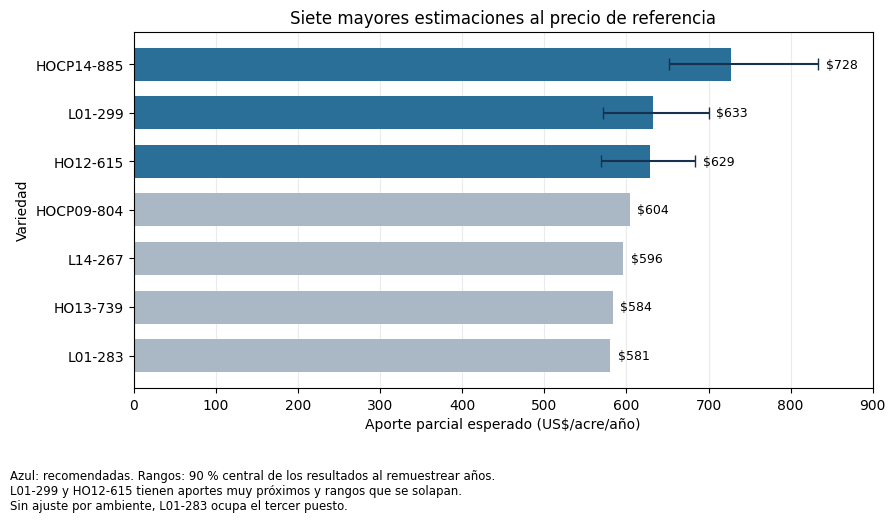

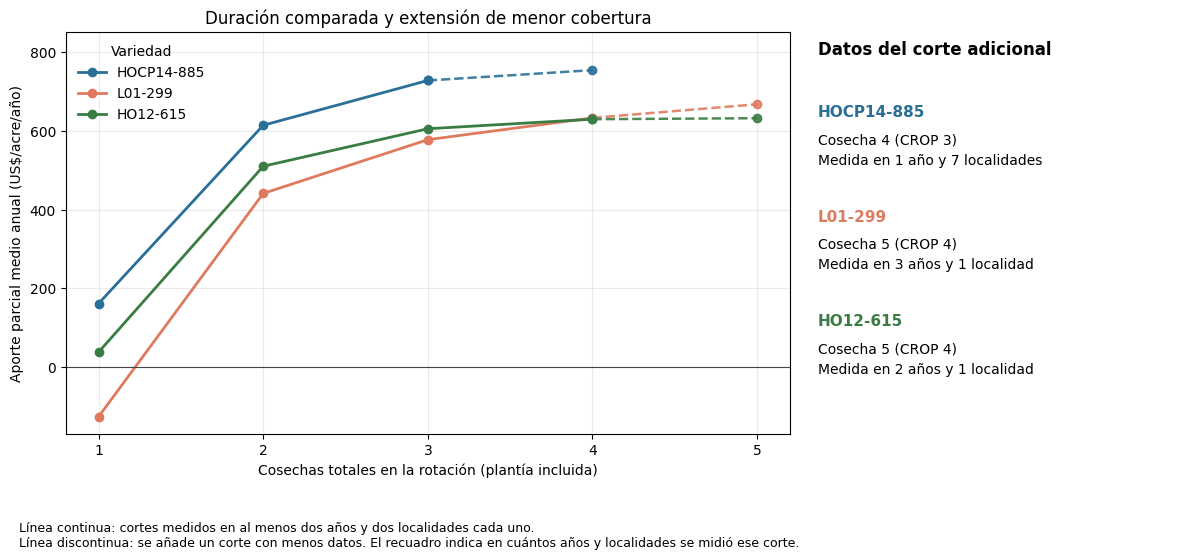

Archivos guardados:
C:\Users\user\Desktop\Cursos\cesar\otros\yo\Prueba Santa Ana\outputs\serie1_economia_ranking.png
C:\Users\user\Desktop\Cursos\cesar\otros\yo\Prueba Santa Ana\outputs\serie1_economia_duracion.png


In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

RUTA_SALIDAS = RUTA_ETL.parent.parent.parent / "outputs"
RUTA_SALIDAS.mkdir(parents=True, exist_ok=True)

# Ranking ajustado y sensibilidad de la posición de las variedades recomendadas.
ranking_figura = mejores.loc[mejores["PRECIO_USD_LB"].eq(0.20)].nlargest(7, "APORTE_ANUAL_USD_ACRE").copy()
ranking_figura = ranking_figura.sort_values("APORTE_ANUAL_USD_ACRE")
recomendadas = set(recomendacion["CLONE"])
colores = ["#2A6F97" if clon in recomendadas else "#A9B8C4" for clon in ranking_figura["CLONE"]]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(ranking_figura["CLONE"], ranking_figura["APORTE_ANUAL_USD_ACRE"], color=colores, height=0.68)
for _, fila in ranking_figura.iterrows():
    p95 = incertidumbre.loc[incertidumbre["CLONE"].eq(fila["CLONE"]), "APORTE_P95"]
    extremo = max(fila["APORTE_ANUAL_USD_ACRE"], float(p95.iloc[0]) if not p95.empty else 0)
    ax.text(extremo + 9, fila["CLONE"], f"${fila['APORTE_ANUAL_USD_ACRE']:,.0f}", va="center", fontsize=9)
recomendacion_por_clon = recomendacion.set_index("CLONE")
for _, fila in incertidumbre.iterrows():
    if fila["CLONE"] in ranking_figura["CLONE"].values:
        estimacion = recomendacion_por_clon.loc[fila["CLONE"], "APORTE_ANUAL_USD_ACRE"]
        ax.errorbar(
            estimacion, fila["CLONE"],
            xerr=[[estimacion - fila["APORTE_P05"]], [fila["APORTE_P95"] - estimacion]],
            fmt="none", ecolor="#16324F", capsize=4, linewidth=1.5, zorder=3,
        )
ax.set_xlim(left=0, right=900)
ax.set_xlabel("Aporte parcial esperado (US$/acre/año)")
ax.set_ylabel("Variedad")
ax.set_title("Siete mayores estimaciones al precio de referencia")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.text(0.01, 0.01,
         "Azul: recomendadas. Rangos: 90 % central de los resultados al remuestrear años.\n"
         "L01-299 y HO12-615 tienen aportes muy próximos y rangos que se solapan.\n"
         "Sin ajuste por ambiente, L01-283 ocupa el tercer puesto.", fontsize=8.5)
fig.tight_layout(rect=(0, 0.13, 1, 1))
fig.savefig(RUTA_SALIDAS / "serie1_economia_ranking.png", dpi=180, bbox_inches="tight")
plt.show()

# Aporte esperado por duración; el tramo discontinuo tiene menor respaldo.
extension_figura = pd.DataFrame(extension)
fig, (ax, datos_corte) = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [2.2, 1.1]})
datos_corte.axis("off")
datos_corte.text(0, 0.98, "Datos del corte adicional", fontsize=12, weight="bold", va="top")
paleta = {"HOCP14-885": "#2A6F97", "L01-299": "#E07A5F", "HO12-615": "#3A7D44"}
for _, decision in recomendacion.iterrows():
    clon = decision["CLONE"]
    color = paleta.get(clon, "#555555")
    serie = politicas.loc[
        politicas["CLONE"].eq(clon) & politicas["PRECIO_USD_LB"].eq(0.20)
    ].sort_values("COSECHAS_TOTALES")
    ax.plot(serie["COSECHAS_TOTALES"], serie["APORTE_ANUAL_USD_ACRE"],
            marker="o", color=color, linewidth=2, label=clon)
    extra = extension_figura.loc[extension_figura["CLONE"].eq(clon)].sort_values("COSECHAS")
    if not extra.empty:
        x0 = int(serie["COSECHAS_TOTALES"].max())
        y0 = float(serie.loc[serie["COSECHAS_TOTALES"].eq(x0), "APORTE_ANUAL_USD_ACRE"].iloc[0])
        x_extra = extra["COSECHAS"].to_numpy()
        y_extra = extra["APORTE"].to_numpy()
        ax.plot([x0, *x_extra], [y0, *y_extra], marker="o", linestyle="--",
                color=color, linewidth=1.8, alpha=0.9)
        punto = extra.iloc[-1]
        cosechas = int(punto["COSECHAS"])
        soporte = resumen_rotacion.loc[
            resumen_rotacion["CLONE"].eq(clon) & resumen_rotacion["CROP"].eq(cosechas - 1)
        ].iloc[0]
        anios = int(soporte["anios"])
        localidades = int(soporte["localidades"])
        texto_anios = "año" if anios == 1 else "años"
        texto_localidades = "localidad" if localidades == 1 else "localidades"
        posicion = {"HOCP14-885": 0.82, "L01-299": 0.56, "HO12-615": 0.30}[clon]
        datos_corte.text(0, posicion, clon, color=color, weight="bold", fontsize=11, va="top")
        datos_corte.text(0, posicion - 0.07,
                         f"Cosecha {cosechas} (CROP {cosechas - 1})\n"
                         f"Medida en {anios} {texto_anios} y {localidades} {texto_localidades}",
                         fontsize=10, va="top", linespacing=1.6)
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_xticks(range(1, 6))
ax.set_xlim(0.8, 5.2)
ax.set_ylim(top=850)
ax.set_xlabel("Cosechas totales en la rotación (plantía incluida)")
ax.set_ylabel("Aporte parcial medio anual (US$/acre/año)")
ax.set_title("Duración comparada y extensión de menor cobertura")
ax.grid(axis="both", alpha=0.25)
ax.legend(title="Variedad", frameon=False)
fig.text(0.02, 0.015,
         "Línea continua: cortes medidos en al menos dos años y dos localidades cada uno.\n"
         "Línea discontinua: se añade un corte con menos datos. El recuadro indica en cuántos años y localidades se midió ese corte.",
         fontsize=9)
fig.tight_layout(rect=(0, 0.11, 1, 1), w_pad=2)
fig.savefig(RUTA_SALIDAS / "serie1_economia_duracion.png", dpi=180, bbox_inches="tight")
plt.show()
print("Archivos guardados:")
print((RUTA_SALIDAS / "serie1_economia_ranking.png").resolve())
print((RUTA_SALIDAS / "serie1_economia_duracion.png").resolve())

## Respuesta para Gerencia (borrador pendiente de revisión)

Recomendaría ampliar **HoCP14-885**, renovándola después de **tres cosechas totales** (plantía + dos socas), y **L01-299** y **Ho12-615**, después de **cuatro cosechas** (plantía + tres socas). Al precio de US$0.20/lb, el aporte parcial anual esperado bajo el ajuste es aproximadamente US$728, US$633 y US$629 por acre, respectivamente. Son políticas iniciales dentro del horizonte con cobertura; no se afirma que una cosecha posterior sea biológicamente imposible o menos rentable.

La certeza es **media para L01-299**, por su amplia historia y estabilidad de duración entre escenarios, aunque la quinta cosecha ofrece mayor aporte en una sola localidad y merece seguimiento. Es **media-baja para HoCP14-885** respecto a duración: destaca económicamente, pero la tercera soca tiene solo un año y queda fuera de la recomendación principal por cobertura. Es **media-baja para Ho12-615 y para el tercer puesto**: su aporte es cercano al de otras variedades y L01-283 la reemplaza al usar promedios directos sin ajuste ambiental. Las diferencias pequeñas no deben tratarse como superioridad demostrada.

Las tres duraciones elegidas permanecen en los escenarios de US$0.15, 0.20 y 0.25/lb; cambia fuertemente el aporte. El remuestreo de años da rangos y frecuencia de repetición de la decisión, no probabilidades de superioridad universal. El precio de US$0.15 no es un límite garantizado: precios más bajos o costos omitidos pueden cambiar la decisión.

Para Gerencia, la política es ampliar con seguimiento y reconsiderar renovación al comparar el aporte esperado de la siguiente soca con el promedio anual de reiniciar la rotación. No se propone una distribución porcentual de hectáreas porque el archivo no contiene superficie ni restricciones de la empresa. La falta de cohortes, costos completos y causas de descarte reduce certeza y orienta los datos propios de la pregunta 4; no impide resolver el ejercicio con supuestos explícitos.